In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/StudentPerformanceFactors.csv')

print(df.head())

   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

  Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality  \
0             Ye

In [5]:
# Checking rows and data type
print(df.shape)
print(df.info())

(6607, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-

In [4]:
# Data cleaning and basic analysis
# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check basic statistics
print(df.describe())

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64
Duplicate rows: 0
       Hours_Studied   Attendance  Sleep_Hours  Previous_Scores  \
count    6607.000000  6607.000000   6607.00000      6607.000000   
mean       19.975329    79.977448      7.02906        75.070531   
std         5.990594    11.547475      1.46812        14.399784   
min         1.000000    60.000000      4.

In [6]:
# Handle missing values
df['Teacher_Quality'] = df['Teacher_Quality'].fillna(df['Teacher_Quality'].mode()[0])

df['Parental_Education_Level'] = df['Parental_Education_Level'].fillna(df['Parental_Education_Level'].mode()[0])

df['Distance_from_Home'] = df['Distance_from_Home'].fillna(df['Distance_from_Home'].mode()[0])

# Check missing values again
print(df.isnull().sum())

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


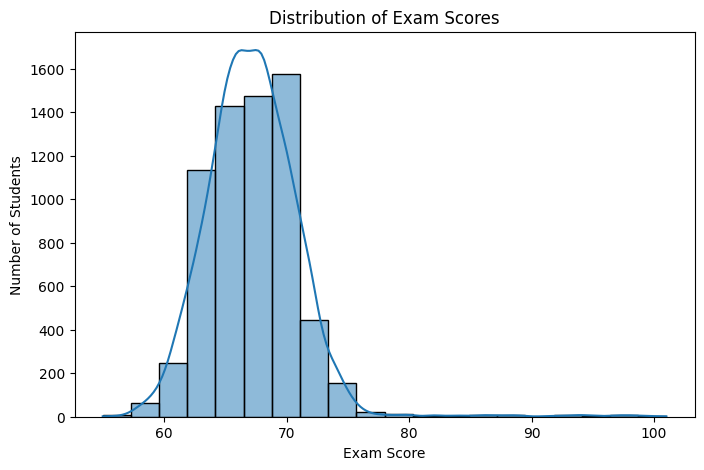

In [7]:
# Exam score distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['Exam_Score'], bins=20, kde=True)
plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')
plt.show()

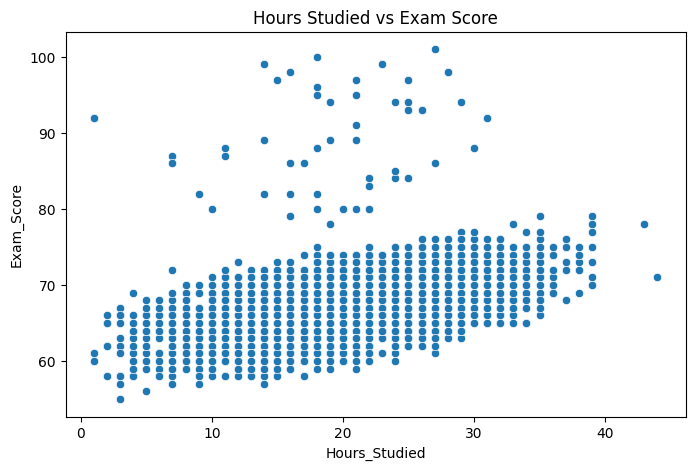

In [8]:
# Hours studied vs exam score
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Hours_Studied', y='Exam_Score')
plt.title('Hours Studied vs Exam Score')
plt.show()

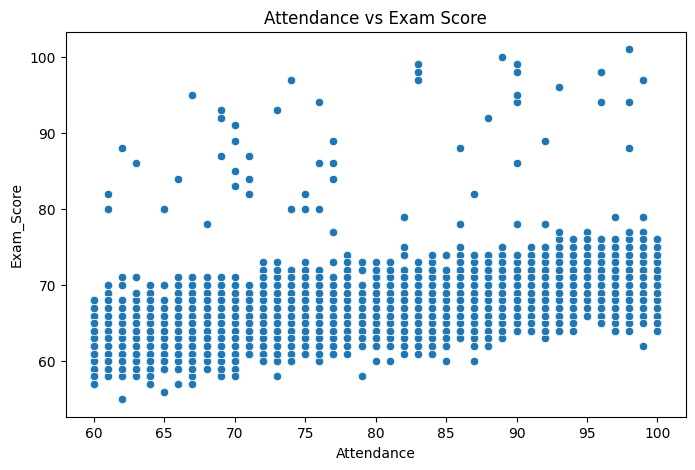

In [9]:
# Attendance vs exam score
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Attendance', y='Exam_Score')
plt.title('Attendance vs Exam Score')
plt.show()

In [10]:
# Convert categorical columns into numerical values
df = pd.get_dummies(df, drop_first=True, dtype=int)

# Separate input features and target variable
X = df.drop('Exam_Score', axis=1)
y = df['Exam_Score']

print(X.shape)
print(y.shape)

(6607, 27)
(6607,)


In [11]:
# Splitting data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5285, 27)
Testing data: (1322, 27)


In [12]:
# Linear Regression Model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.45239200896259657
RMSE: 1.804444509272284
R2 Score: 0.7696495724907312


In [13]:
# Random Forest Model
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", mean_squared_error(y_test, rf_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, rf_pred))

MAE: 1.183782148260212
RMSE: 2.2332001488200435
R2 Score: 0.6471767007776992


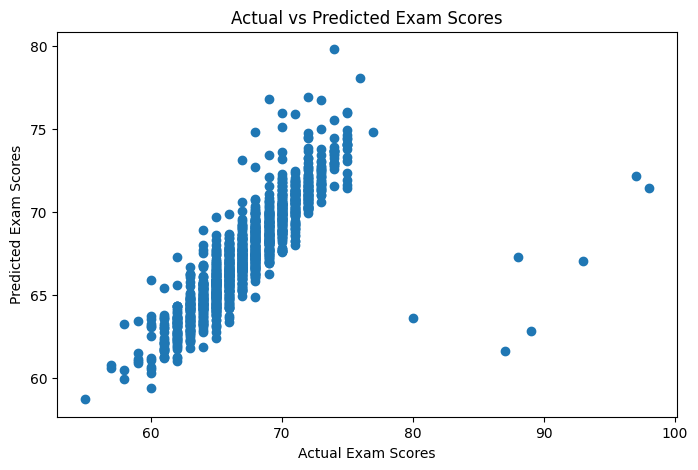

In [14]:
# Step 8: Compare actual exam scores with predicted scores

plt.figure(figsize=(8, 5))

# Plot actual and predicted scores
plt.scatter(y_test, rf_pred)

# Add graph labels and title
plt.xlabel('Actual Exam Scores')
plt.ylabel('Predicted Exam Scores')
plt.title('Actual vs Predicted Exam Scores')

# Display the graph
plt.show()

In [15]:
# Step 9: Compare Linear Regression and Random Forest results

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    'RMSE': [
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_squared_error(y_test, rf_pred) ** 0.5
    ],
    'R2 Score': [
        r2_score(y_test, y_pred),
        r2_score(y_test, rf_pred)
    ]
})

print(results)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  0.452392  1.804445  0.769650
1      Random Forest  1.183782  2.233200  0.647177


Attendance                               0.380896
Hours_Studied                            0.242241
Previous_Scores                          0.092234
Tutoring_Sessions                        0.039065
Sleep_Hours                              0.027021
Physical_Activity                        0.026876
Parental_Involvement_Low                 0.020537
Access_to_Resources_Low                  0.017597
Access_to_Resources_Medium               0.011180
Parental_Education_Level_Postgraduate    0.010913
dtype: float64


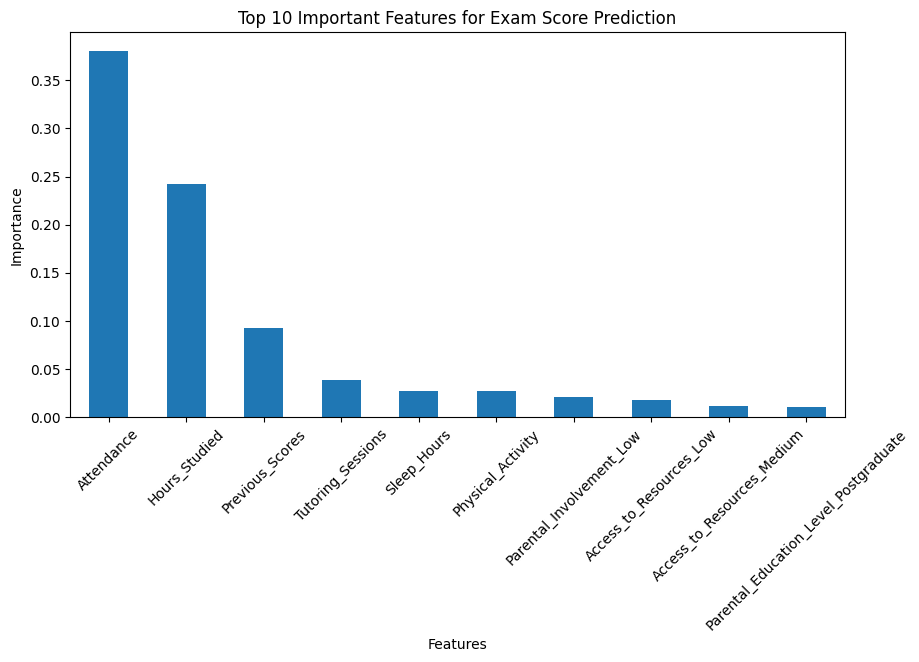

In [16]:
# Step 10: Display the importance of each feature in Random Forest

importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(ascending=False)

# Display top 10 important features
print(importance.head(10))

# Plot top 10 important features
importance.head(10).plot(kind='bar', figsize=(10, 5))

plt.title('Top 10 Important Features for Exam Score Prediction')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=45)
plt.show()

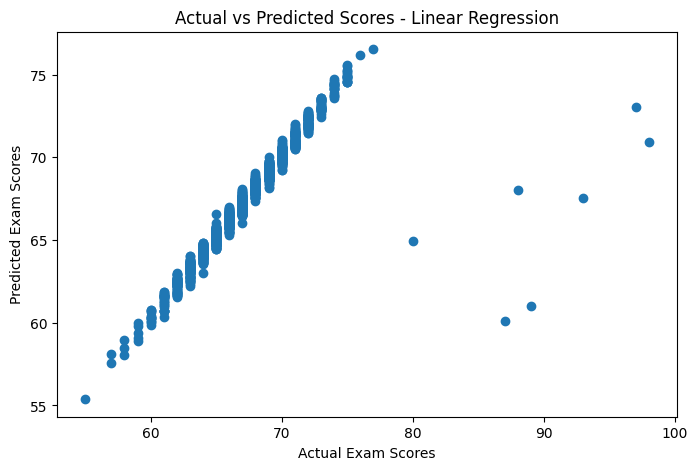

In [17]:
# Step 11: Compare actual and predicted scores using Linear Regression

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Exam Scores')
plt.ylabel('Predicted Exam Scores')
plt.title('Actual vs Predicted Scores - Linear Regression')

plt.show()

In [19]:
# Step 12: Predict & compare the exam score of a sample student

sample_student = X_test.iloc[[0]]

actual_score = y_test.iloc[0]
predicted_score = model.predict(sample_student)[0]

print("Actual Exam Score:", actual_score)
print("Predicted Exam Score:", round(predicted_score, 2))
print("Prediction Error:", round(abs(actual_score - predicted_score), 2))

Actual Exam Score: 65
Predicted Exam Score: 64.53
Prediction Error: 0.47
